Do vocal biomarkers consistently distinguish Parkinson's patients from healthy individuals?
=
<p>This project explores the possibility that vocal biomarkers can be used as an early screening tool for detecting whether a patient has Parkinson's disease. Using a dataset that recorded 23 different biomarkers in the speech of a large number of patients, we narrow in on a few features to see whether they are correlated with and able to predict the incidence of Parkinson's in a given group of patients.</p>

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy
import numpy as np

In [2]:
parkdf = pd.read_csv("dataset.csv")

In [3]:
parkdf.shape

(1195, 24)

In [4]:
parkdf.head(10)

,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.033,1.0,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.085,1.0,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.651,1.0,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.08771,0.01353,20.644,1.0,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.10470,0.01767,19.649,1.0,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335
5,phon_R01_S01_6,120.552,131.162,113.787,0.00968,0.00008,0.00463,0.00750,0.01388,0.04701,...,0.06985,0.01222,21.378,1.0,0.415564,0.825069,-4.242867,0.299111,2.187560,0.357775
6,phon_R01_S02_1,120.267,137.244,114.820,0.00333,0.00003,0.00155,0.00202,0.00466,0.01608,...,0.02337,0.00607,24.886,1.0,0.596040,0.764112,-5.634322,0.257682,1.854785,0.211756
7,phon_R01_S02_2,107.332,113.840,104.315,0.00290,0.00003,0.00144,0.00182,0.00431,0.01567,...,0.02487,0.00344,26.892,1.0,0.637420,0.763262,-6.167603,0.183721,2.064693,0.163755
8,phon_R01_S02_3,95.730,132.068,91.754,0.00551,0.00006,0.00293,0.00332,0.00880,0.02093,...,0.03218,0.01070,21.812,1.0,0.615551,0.773587,-5.498678,0.327769,2.322511,0.231571
9,phon_R01_S02_4,95.056,120.103,91.226,0.00532,0.00006,0.00268,0.00332,0.00803,0.02838,...,0.04324,0.01022,21.862,1.0,0.547037,0.798463,-5.011879,0.325996,2.432792,0.271362


In [5]:
parkdf.info()

<class 'pandas.DataFrame'>
RangeIndex: 1195 entries, 0 to 1194
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              1195 non-null   str    
 1   MDVP:Fo(Hz)       1195 non-null   float64
 2   MDVP:Fhi(Hz)      1195 non-null   float64
 3   MDVP:Flo(Hz)      1195 non-null   float64
 4   MDVP:Jitter(%)    1195 non-null   float64
 5   MDVP:Jitter(Abs)  1195 non-null   float64
 6   MDVP:RAP          1195 non-null   float64
 7   MDVP:PPQ          1195 non-null   float64
 8   Jitter:DDP        1195 non-null   float64
 9   MDVP:Shimmer      1195 non-null   float64
 10  MDVP:Shimmer(dB)  1195 non-null   float64
 11  Shimmer:APQ3      1195 non-null   float64
 12  Shimmer:APQ5      1195 non-null   float64
 13  MDVP:APQ          1195 non-null   float64
 14  Shimmer:DDA       1195 non-null   float64
 15  NHR               1195 non-null   float64
 16  HNR               1195 non-null   float64
 17  status

In [6]:
parkdf.describe()

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
count,1195.000000,1195.000000,1195.000000,1195.000000,1195.000000,1195.000000,1195.000000,1195.000000,1195.000000,1195.000000,...,1195.000000,1195.000000,1195.000000,1195.000000,1195.000000,1195.000000,1195.000000,1195.000000,1195.000000,1195.000000
mean,154.312848,197.246916,116.332971,0.006221,0.000044,0.003306,0.003428,0.009920,0.029671,0.282587,...,0.047084,0.024880,21.895992,0.754117,0.498054,0.718214,-5.683541,0.226451,2.382126,0.206771
std,17.124313,37.804828,17.953210,0.002001,0.000014,0.001228,0.001140,0.003678,0.007781,0.080554,...,0.012609,0.016717,1.829752,0.178176,0.043021,0.022905,0.451130,0.034527,0.157783,0.037229
min,88.333000,102.145000,65.476000,0.001680,0.000007,0.000680,0.000920,0.002040,0.009540,0.085000,...,0.013640,0.000650,8.441000,0.000000,0.256570,0.574282,-7.964984,0.006274,1.423287,0.044539
25%,150.616420,189.666263,112.204966,0.005769,0.000041,0.003012,0.003173,0.009089,0.027992,0.264388,...,0.044325,0.020837,21.550002,0.726172,0.489091,0.713742,-5.779205,0.219263,2.351569,0.199061
50%,154.117666,197.198334,116.100612,0.006188,0.000044,0.003282,0.003397,0.009845,0.029575,0.280555,...,0.046820,0.024486,21.913050,0.758665,0.497781,0.718387,-5.681992,0.226621,2.382482,0.207056
75%,157.491303,204.071906,119.290367,0.006557,0.000046,0.003530,0.003618,0.010552,0.031008,0.296840,...,0.049418,0.027661,22.274815,0.797437,0.506417,0.722957,-5.595197,0.232901,2.411210,0.213564
max,260.105000,592.030000,239.170000,0.033160,0.000260,0.021440,0.019580,0.064330,0.119080,1.302000,...,0.169420,0.314820,33.047000,1.000000,0.685151,0.825288,-2.434031,0.450493,3.671155,0.527367


In [7]:
parkdf.isna().sum()

name                0
MDVP:Fo(Hz)         0
MDVP:Fhi(Hz)        0
MDVP:Flo(Hz)        0
MDVP:Jitter(%)      0
MDVP:Jitter(Abs)    0
MDVP:RAP            0
MDVP:PPQ            0
Jitter:DDP          0
MDVP:Shimmer        0
MDVP:Shimmer(dB)    0
Shimmer:APQ3        0
Shimmer:APQ5        0
MDVP:APQ            0
Shimmer:DDA         0
NHR                 0
HNR                 0
status              0
RPDE                0
DFA                 0
spread1             0
spread2             0
D2                  0
PPE                 0
dtype: int64

In [8]:
parkdf.duplicated().sum()

np.int64(0)

Cleaning Log:
=
The following bullet points describe work performed in subsequent cells.
- Dataset contains 1195 rows total with 24 columns.
- Dataset contained zero rows with missing values and zero duplicated rows.
- The first column, "name", is a patient ID number, which functions as a unique identifier and also anonymizes PII.
- All other columns are "float" dtypes, meaning they are decimal values and can have statistical analysis applied to them without needing conversion to another dtype first.
- The "status" column represents whether the patient is diagnosed with Parkinson's. Healthy individuals have "status"=0 and diagnosed patients have "status"=1
- However, there is a major issue: "status" should be a binary category (value = 0 or 1), but 1000 rows have unique non-binary decimal "status" values instead of 0 or 1
- There is no way to know the correct "status" values of those 1000 rows. Discussion on the dataset's Kaggle page points out this large error; response is "We will fix those errors in the next version, please stay connected."
- The difficult decision is made to exclude those 1000 rows to avoid introducing noise into the data. I will work with the remaining 195 rows instead and make note that the much smaller sample size limits any conclusions.

To address the stated research question, I will compare the rows with "status"=1 (Parkinson's patients) against rows with "status"=0 (healthy individuals). For that reason, I want to see which columns correlate most strongly with the "status" column.

In [9]:
parkdf.groupby("status").mean(numeric_only=True)

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,MDVP:APQ,Shimmer:DDA,NHR,HNR,RPDE,DFA,spread1,spread2,D2,PPE
status,,,,,,,,,,,,,,,,,,,,,
0.000000,181.937771,223.636750,145.207292,0.003866,0.000023,0.001925,0.002056,0.005776,0.017615,0.162958,...,0.013305,0.028511,0.011483,24.678750,0.442552,0.695716,-6.759264,0.160292,2.154491,0.123017
0.575556,149.198447,207.415543,111.482874,0.006078,0.000040,0.003701,0.003331,0.008534,0.031243,0.275112,...,0.024103,0.049216,0.026544,21.318538,0.501891,0.725354,-5.564950,0.209877,2.380827,0.206444
0.615667,153.886563,199.401599,121.363146,0.005983,0.000047,0.003138,0.003550,0.009534,0.026432,0.282593,...,0.023219,0.048064,0.034362,22.159939,0.493306,0.721284,-5.490661,0.214860,2.363735,0.225016
0.625442,152.157607,207.259044,116.464707,0.005995,0.000044,0.003535,0.003458,0.010400,0.032165,0.256628,...,0.024626,0.047195,0.020836,21.418531,0.477161,0.718057,-5.581980,0.225841,2.369936,0.211201
0.627344,153.080931,202.680710,113.269057,0.006523,0.000046,0.003239,0.003415,0.009060,0.029728,0.271875,...,0.024869,0.048402,0.022129,21.939683,0.498502,0.723707,-5.823857,0.221358,2.384068,0.195353
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
0.865840,152.466878,192.782541,120.296634,0.005874,0.000044,0.003664,0.003540,0.010088,0.029207,0.309389,...,0.026209,0.048204,0.027789,21.525414,0.493623,0.717218,-5.698483,0.218747,2.350404,0.193617
0.875026,159.428126,188.703201,113.941707,0.006447,0.000041,0.002958,0.003123,0.008723,0.029753,0.290140,...,0.025242,0.043531,0.025270,21.984162,0.510846,0.718195,-5.670870,0.228618,2.354472,0.197873
0.877561,155.771643,195.171568,115.100600,0.005912,0.000049,0.002894,0.003737,0.009543,0.026965,0.313777,...,0.025692,0.044149,0.027168,20.991225,0.500720,0.719314,-5.711304,0.230594,2.399800,0.209875


In [10]:
parkdf[~parkdf["status"].isin([0, 1])]

,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
195,synth_2746,155.771643,195.171568,115.100600,0.005912,0.000049,0.002894,0.003737,0.009543,0.026965,...,0.044149,0.027168,20.991225,0.877561,0.500720,0.719314,-5.711304,0.230594,2.399800,0.209875
196,synth_9887,152.599769,193.821528,112.795875,0.005749,0.000044,0.003345,0.004124,0.011496,0.030349,...,0.051060,0.025007,21.961898,0.726548,0.503811,0.714226,-5.868877,0.213131,2.335698,0.208612
197,synth_5725,160.852032,217.470912,110.813098,0.006097,0.000040,0.003048,0.003029,0.010069,0.029881,...,0.046218,0.017968,21.737005,0.743267,0.500353,0.719177,-5.659510,0.246248,2.395728,0.210055
198,synth_8286,150.999262,207.571598,115.009521,0.006249,0.000041,0.003494,0.003465,0.010897,0.034397,...,0.047870,0.028738,21.454898,0.795142,0.489332,0.718513,-5.640818,0.237929,2.415242,0.221670
199,synth_8631,152.461018,206.220252,120.777286,0.006888,0.000044,0.003693,0.003324,0.009686,0.031145,...,0.047737,0.027261,22.541867,0.690255,0.497636,0.721675,-5.907361,0.225822,2.403034,0.213173
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1190,synth_7756,151.028206,179.206312,118.797466,0.006594,0.000040,0.003458,0.003513,0.008731,0.027186,...,0.050788,0.021377,21.884979,0.736271,0.499528,0.727604,-5.772439,0.234236,2.392305,0.210778
1191,synth_5355,161.752472,211.299774,114.784598,0.006397,0.000045,0.003545,0.003017,0.009591,0.028982,...,0.049785,0.020925,21.973752,0.798377,0.499209,0.728558,-5.604039,0.235680,2.362850,0.209570
1192,synth_6356,148.323186,194.399282,118.570170,0.006335,0.000044,0.003483,0.003386,0.008980,0.029598,...,0.051215,0.021530,21.615298,0.771907,0.497459,0.717687,-5.770640,0.233789,2.410545,0.223595
1193,synth_7098,152.106305,209.880095,112.903699,0.005298,0.000041,0.002778,0.003506,0.009388,0.029550,...,0.049023,0.026806,21.561977,0.704315,0.486495,0.722529,-5.677169,0.236918,2.427505,0.218734


The "status" column has poorly formatted rows. Below, I explore what these rows look like and ultimately exclude them from analysis.

In [11]:
wstat = parkdf[~parkdf["status"].isin([0, 1])]

In [12]:
wstat.shape

(1000, 24)

In [13]:
wstat["status"].nunique()

1000


Every erroneous row has a completely unique value for "status", which means there is no pattern that could indicate which rows correctly belong to which group. Because these 1000 rows are unreliable, I will exclude them from our working data and use the rows that are left.

In [14]:
park2df = parkdf[parkdf["status"].isin([0,1])]

In [15]:
park2df.shape

(195, 24)

This is a much smaller number of rows, but is still a large enough sample size to perform analysis on.

In [16]:
park2df.head(10)

,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.033,1.0,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.085,1.0,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.651,1.0,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.08771,0.01353,20.644,1.0,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.10470,0.01767,19.649,1.0,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335
5,phon_R01_S01_6,120.552,131.162,113.787,0.00968,0.00008,0.00463,0.00750,0.01388,0.04701,...,0.06985,0.01222,21.378,1.0,0.415564,0.825069,-4.242867,0.299111,2.187560,0.357775
6,phon_R01_S02_1,120.267,137.244,114.820,0.00333,0.00003,0.00155,0.00202,0.00466,0.01608,...,0.02337,0.00607,24.886,1.0,0.596040,0.764112,-5.634322,0.257682,1.854785,0.211756
7,phon_R01_S02_2,107.332,113.840,104.315,0.00290,0.00003,0.00144,0.00182,0.00431,0.01567,...,0.02487,0.00344,26.892,1.0,0.637420,0.763262,-6.167603,0.183721,2.064693,0.163755
8,phon_R01_S02_3,95.730,132.068,91.754,0.00551,0.00006,0.00293,0.00332,0.00880,0.02093,...,0.03218,0.01070,21.812,1.0,0.615551,0.773587,-5.498678,0.327769,2.322511,0.231571
9,phon_R01_S02_4,95.056,120.103,91.226,0.00532,0.00006,0.00268,0.00332,0.00803,0.02838,...,0.04324,0.01022,21.862,1.0,0.547037,0.798463,-5.011879,0.325996,2.432792,0.271362


In [17]:
park2df.info()

<class 'pandas.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              195 non-null    str    
 1   MDVP:Fo(Hz)       195 non-null    float64
 2   MDVP:Fhi(Hz)      195 non-null    float64
 3   MDVP:Flo(Hz)      195 non-null    float64
 4   MDVP:Jitter(%)    195 non-null    float64
 5   MDVP:Jitter(Abs)  195 non-null    float64
 6   MDVP:RAP          195 non-null    float64
 7   MDVP:PPQ          195 non-null    float64
 8   Jitter:DDP        195 non-null    float64
 9   MDVP:Shimmer      195 non-null    float64
 10  MDVP:Shimmer(dB)  195 non-null    float64
 11  Shimmer:APQ3      195 non-null    float64
 12  Shimmer:APQ5      195 non-null    float64
 13  MDVP:APQ          195 non-null    float64
 14  Shimmer:DDA       195 non-null    float64
 15  NHR               195 non-null    float64
 16  HNR               195 non-null    float64
 17  status  

In [18]:
park2df.describe()

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
count,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,...,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000
mean,154.228641,197.104918,116.324631,0.006220,0.000044,0.003306,0.003446,0.009920,0.029709,0.282251,...,0.046993,0.024847,21.885974,0.753846,0.498536,0.718099,-5.684397,0.226510,2.381826,0.206552
std,41.390065,91.491548,43.521413,0.004848,0.000035,0.002968,0.002759,0.008903,0.018857,0.194877,...,0.030459,0.040418,4.425764,0.431878,0.103942,0.055336,1.090208,0.083406,0.382799,0.090119
min,88.333000,102.145000,65.476000,0.001680,0.000007,0.000680,0.000920,0.002040,0.009540,0.085000,...,0.013640,0.000650,8.441000,0.000000,0.256570,0.574282,-7.964984,0.006274,1.423287,0.044539
25%,117.572000,134.862500,84.291000,0.003460,0.000020,0.001660,0.001860,0.004985,0.016505,0.148500,...,0.024735,0.005925,19.198000,1.000000,0.421306,0.674758,-6.450096,0.174351,2.099125,0.137451
50%,148.790000,175.829000,104.315000,0.004940,0.000030,0.002500,0.002690,0.007490,0.022970,0.221000,...,0.038360,0.011660,22.085000,1.000000,0.495954,0.722254,-5.720868,0.218885,2.361532,0.194052
75%,182.769000,224.205500,140.018500,0.007365,0.000060,0.003835,0.003955,0.011505,0.037885,0.350000,...,0.060795,0.025640,25.075500,1.000000,0.587562,0.761881,-5.046192,0.279234,2.636456,0.252980
max,260.105000,592.030000,239.170000,0.033160,0.000260,0.021440,0.019580,0.064330,0.119080,1.302000,...,0.169420,0.314820,33.047000,1.000000,0.685151,0.825288,-2.434031,0.450493,3.671155,0.527367


Exploratory analysis
=
<p>The newly cleaned dataset should now function in terms of splitting the rows into two groups: Healthy individuals versus those with Parkinson's. I will take a look at the mean and median of the two groups, then see which columns correlate most strongly with patient status.</p>

In [19]:
park2df.groupby("status").mean(numeric_only=True)

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,MDVP:APQ,Shimmer:DDA,NHR,HNR,RPDE,DFA,spread1,spread2,D2,PPE
status,,,,,,,,,,,,,,,,,,,,,
0.0,181.937771,223.636750,145.207292,0.003866,0.000023,0.001925,0.002056,0.005776,0.017615,0.162958,...,0.013305,0.028511,0.011483,24.678750,0.442552,0.695716,-6.759264,0.160292,2.154491,0.123017
1.0,145.180762,188.441463,106.893558,0.006989,0.000051,0.003757,0.003900,0.011273,0.033658,0.321204,...,0.027600,0.053027,0.029211,20.974048,0.516816,0.725408,-5.333420,0.248133,2.456058,0.233828


In [20]:
park2df.groupby("status").median(numeric_only=True)

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,MDVP:APQ,Shimmer:DDA,NHR,HNR,RPDE,DFA,spread1,spread2,D2,PPE
status,,,,,,,,,,,,,,,,,,,,,
0.0,198.996,231.1615,113.9385,0.003355,0.000025,0.001625,0.001775,0.004875,0.016705,0.154,...,0.013015,0.02633,0.004825,24.997,0.435368,0.682527,-6.826448,0.167356,2.129510,0.115118
1.0,145.174,163.3350,99.7700,0.005440,0.000040,0.002840,0.003140,0.008530,0.028380,0.263,...,0.021570,0.04451,0.016580,21.414,0.530529,0.726652,-5.440040,0.240875,2.439597,0.222716


In [21]:
park2df.corrwith(park2df["status"], numeric_only=True)

MDVP:Fo(Hz)        -0.383535
MDVP:Fhi(Hz)       -0.166136
MDVP:Flo(Hz)       -0.380200
MDVP:Jitter(%)      0.278220
MDVP:Jitter(Abs)    0.338653
MDVP:RAP            0.266668
MDVP:PPQ            0.288698
Jitter:DDP          0.266646
MDVP:Shimmer        0.367430
MDVP:Shimmer(dB)    0.350697
Shimmer:APQ3        0.347617
Shimmer:APQ5        0.351148
MDVP:APQ            0.364316
Shimmer:DDA         0.347608
NHR                 0.189429
HNR                -0.361515
status              1.000000
RPDE                0.308567
DFA                 0.231739
spread1             0.564838
spread2             0.454842
D2                  0.340232
PPE                 0.531039
dtype: float64

<Axes: >

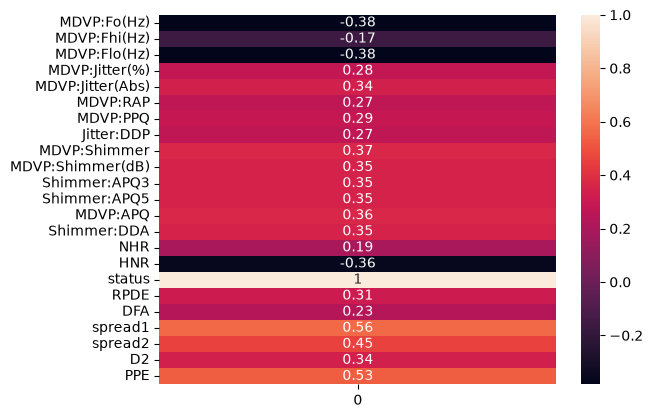

In [22]:
sns.heatmap(park2df.corrwith(park2df["status"], numeric_only=True).to_frame(), annot=True)

Based on the above correlation diagram, I will examine the following two columns because they have the largest absolute r values:
- PPE (Pitch Period Entropy): This unitless variable represents how regular the pitch period was. Put another way, it represents whether a person takes an inconsistent amount of time to produce sounds.
- spread1: This variable (no unit specified) measured variation in voice frequency. That is, it represents how much a person's voice has inconsistent pitch.

Next, let us see an overview of how Parkinson's patients compare to healthy individuals on these two variables.

<function matplotlib.pyplot.show(close=None, block=None)>

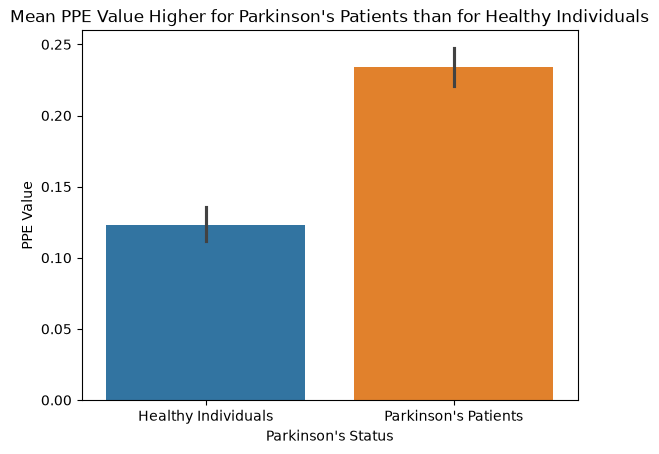

In [23]:
ax1 = sns.barplot(data=park2df, x="status", y="PPE", hue="status", legend=False)
ax1.set_xticks([0,1])
ax1.set_xticklabels(["Healthy Individuals", "Parkinson's Patients"])
plt.title("Mean PPE Value Higher for Parkinson's Patients than for Healthy Individuals")
plt.xlabel("Parkinson's Status")
plt.ylabel("PPE Value")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

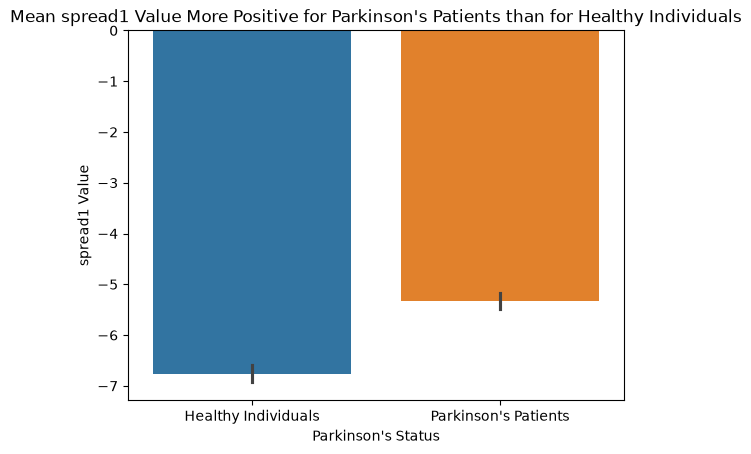

In [24]:
ax2 = sns.barplot(data=park2df, x="status", y="spread1", hue="status", legend=False)
ax2.set_xticks([0,1])
ax2.set_xticklabels(["Healthy Individuals", "Parkinson's Patients"])
plt.title("Mean spread1 Value More Positive for Parkinson's Patients than for Healthy Individuals")
plt.xlabel("Parkinson's Status")
plt.ylabel("spread1 Value")
plt.show

For the mean of both variables, Parkinson's patients score higher. This means that on average, Parkinson's patients have more varying vocal pitch and take more varied amounts of time to speak than healthy individuals. But the above charts only examine the means for each variable. Let us take a closer look at the range, quartiles, and medians of each variable and patient group.

<function matplotlib.pyplot.show(close=None, block=None)>

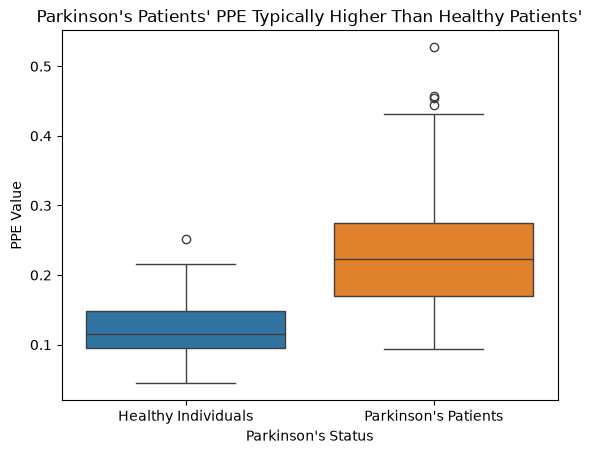

In [25]:
ax3 = sns.boxplot(data=park2df, x="status", y="PPE", hue="status", legend=False)
ax3.set_xticks([0,1])
ax3.set_xticklabels(["Healthy Individuals", "Parkinson's Patients"])
plt.title("Parkinson's Patients' PPE Typically Higher Than Healthy Patients'")
plt.xlabel("Parkinson's Status")
plt.ylabel("PPE Value")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

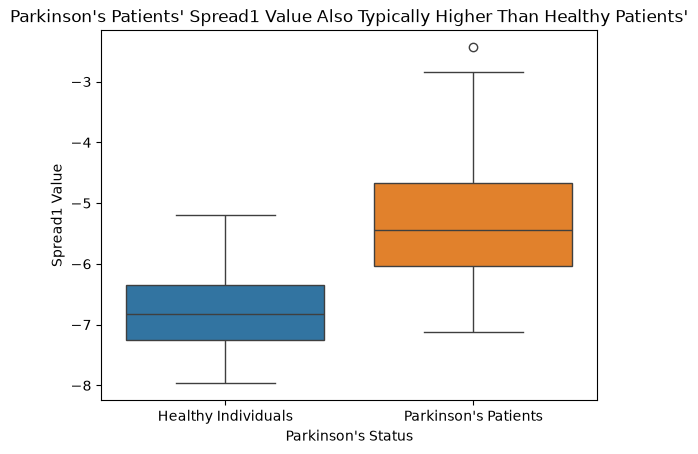

In [26]:
ax4 = sns.boxplot(data=park2df, x="status", y="spread1", hue="status", legend=False)
ax4.set_xticks([0,1])
ax4.set_xticklabels(["Healthy Individuals", "Parkinson's Patients"])
plt.title("Parkinson's Patients' Spread1 Value Also Typically Higher Than Healthy Patients'")
plt.xlabel("Parkinson's Status")
plt.ylabel("Spread1 Value")
plt.show

<p>For both of these variables, the means and interquartile ranges appear quite different for the two groups.</p>

Comparative analysis
=
<p>I will perform a t-test for each variable to determine whether the difference between healthy individuals and Parkinson's patients is statistically significant.</p>

PPE t-Test
-
<p>The null hypothesis is that there is no significant difference in PPE between the two groups. </p>
<p>The alternative hypothesis is that the mean PPE of Parkinson's patients is significantly higher than that of healthy individuals.</p>

spread1 t-Test
-
<p>The null hypothesis is that there is no significant difference in spread1 values between the two groups. </p>
<p>The alternative hypothesis is that the mean spread1 value of Parkinson's patients is significantly higher than that of healthy individuals.</p>

In [27]:
from scipy.stats import ttest_ind

In [28]:
a1 = park2df[park2df["status"] == 0.0]["PPE"]
b1 = park2df[park2df["status"] == 1.0]["PPE"]

t, p = ttest_ind(a1, b1, equal_var=False)

print("Mean PPE value of healthy individuals:", round(a1.mean(),3))
print("Mean PPE value of Parkinson's patients:", round(b1.mean(),3))
print("Difference in mean PPE:", round(b1.mean() - a1.mean(),3))
print("t-statistic:", t)
print("p-value:", p)

Mean PPE value of healthy individuals: 0.123
Mean PPE value of Parkinson's patients: 0.234
Difference in mean PPE: 0.111
t-statistic: -11.670090179718107
p-value: 6.764318285836851e-23


t-Test Results for PPE
-
<p>The absolute value of the t-statistic, which compares the difference in means to the standard error, was very high, meaning that the difference in means far outstrips the amount of noise in the data. The p-value, which is the probability that a t-statistic this extreme would be the result of random chance, is very very low.</p>
    
<p>Healthy individuals had a mean PPE value of 0.123, whereas that of Parkinson's patients was 0.234. This 0.111 difference in mean PPE is statistically significant both because the p-value is low and the absolute value of the t-statistic is high, meaning that the means were very different and there is an extremely small likelihood of that difference resulting from random chance.</p> 

<p>For this reason, I reject the null hypothesis in favor of the alternative hypothesis: There is a significant difference in PPE between Parkinson's patients and healthy individuals.</p>

In [29]:
a2 = park2df[park2df["status"] == 0.0]["spread1"]
b2 = park2df[park2df["status"] == 1.0]["spread1"]

t, p = ttest_ind(a2, b2, equal_var=False)

print("Mean PPE value of healthy individuals:", round(a2.mean(),3))
print("Mean PPE value of Parkinson's patients:", round(b2.mean(),3))
print("Difference in mean spread1:", round(b2.mean() - a2.mean(),3))
print("t-value:", t)
print("p-value:", p)

Mean PPE value of healthy individuals: -6.759
Mean PPE value of Parkinson's patients: -5.333
Difference in mean spread1: 1.426
t-value: -11.634674547436209
p-value: 1.769223693117403e-21


t-Test Results for spread1
-
<p>Bearing in mind the definitions of the t-statistic and p-value described in the previous test, I see that the absolute value of the t-statistic is again very high and the p-value is again extremely low.</p>

<p>Healthy individuals had a mean spread1 value of -6.759, whereas that of Parkinson's patients was -5.333, meaning the mean spread1 of Parkinson's patients was higher by a difference of 1.426. This difference is statistically significant both because of the very low p-value and the high absolute value of the t-statistic.</p>

<p>As a result, I again reject the null hypothesis in favor of the alternative hypothesis: There is a significant difference in spread1 between Parkinson's patients and healthy individuals.</p>

Predicting Future Parkinson's Cases
-
<p>Now that there is reason to believe that there is a relationship between patient status and the two variables of PPE and spread1, it is useful to see whether either variable can be used to predict given patient's Parkinson's status.</p>

<p>I will train a k-nearest neighbor (knn) model on each of the "PPE" and "spread1" columns to predict the health status of a given patient. To determine the model's accuracy, I will split the dataset into 70% training and 30% testing segments. I will train two separate models, one on each variable, train on the training segment, test on the testing segment, then score the models' accuracy in the testing segments.</p>

In [30]:
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

In [31]:
pX = park2df[["PPE"]]
py = park2df["status"]

In [32]:
pX_train, pX_test, py_train, py_test = train_test_split(
    pX, py, test_size=0.3, random_state=42)

In [33]:
print(len(pX_train))
print(len(pX_test))
print(len(py_train))
print(len(py_test))

136
59
136
59


In [34]:
knnp = KNeighborsClassifier(n_neighbors=5)

In [35]:
knnp.fit(pX_train, py_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[float64](2,)","[0.,1.]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [36]:
predp = knnp.predict(pX_test)

In [37]:
print(knnp.score(pX_test, py_test))

0.8813559322033898


Above, I see that the knn model I trained on the training segment of PPE values was able to accurately predict a patient's Parkinson's status for approximately 88.136% of testing rows. Next, I will create another knn model using the spread1 column.

In [38]:
sX = park2df[["spread1"]]
sy = park2df["status"]

In [39]:
sX_train, sX_test, sy_train, sy_test = train_test_split(
    sX, sy, test_size=0.3, random_state=42)

In [40]:
print(len(sX_train))
print(len(sX_test))
print(len(sy_train))
print(len(sy_test))

136
59
136
59


In [41]:
knns = KNeighborsClassifier(n_neighbors=5)

In [42]:
knns.fit(sX_train, sy_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[float64](2,)","[0.,1.]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [43]:
preds = knns.predict(sX_test)

In [44]:
print(knns.score(sX_test, sy_test))

0.8813559322033898


The knn model trained on the spread1 training set also achieved an accuracy of 88.136% when used to predict the Parkinson's status of testing rows. The identical score seems a bit odd, so let us quickly check whether the prediction for each row was identical across the two models:

In [45]:
print("Predictions identical:", (predp == preds).all())

Predictions identical: False


As odd as the coincidence may be, it appears that the two knn models did not predict the same "status" value for each row. That is, the first model may have gotten row A incorrect, while the second model predicted it correctly--but in total, both had the same ratio of successes to failures.

Conclusions and Caution
=
<p>Based on the two t-tests that were performed, there is most likely a strong correlation between "status" and "PPE", and between "status" and "spread1". While this can open the door for meaningful follow-up research, it must be stressed that correlation does not equal causation, so I cannot say with any certainty that Parkinson's disease causes high "PPE" values or high "spread1" values. For example, it is possible that both Parkinson's and PPE are downstream of a more fundamental, unidentified health issue, such that the two are often comorbid.</p>

<p>I was able to train a knn model for each of the two variables and both models performed on the test data with reasonable, though nowhere near airtight, accuracy. For that reason, the knn models are most useful as an initial exploratory tool for narrowing down large groups of patients into initial rows of interest, but not as a final decision-making tool.</p>

<p>Additionally, it must be noted that the rows I worked with were a very small subset of the original dataset because the overwhelming majority of rows had erroneous "status" values. This is particularly vexing because "status" was the target I was attempting to predict using the features of "PPE" and "spread1". As a result, care should be taken not to extrapolate from the results in this project; instead, this project should be used as a reason to correct the errors in the original dataset then run these analyses again. If a strong pattern emerges at that point, it could then be possible that stronger conclusions could be drawn.</p>
    
<p>Ultimately, while I cannot claim causation, the analysis here nonetheless promises value in further investigating vocal biomarkers as an early detection tool for Parkinson's. </p>

References
=
<p>The dataset used for this project is: <br>
Shreya Dutta. (2024). Parkinson's Disease [Dataset]. Kaggle. https://doi.org/10.34740/KAGGLE/DSV/9759604</p>

<p>I also consulted the pandas, seaborn, and SciPy User Guides, the websites Geeks for Geeks and LeafCoding, and various Stack Overflow posts: <br>
<font color=gray><i><a>https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.mode.html</a> <br>
<a>https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.isin.html</a> <br>
<a>https://seaborn.pydata.org/generated/seaborn.barplot.html</a> <br>
<a>https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html</a> <br>
<a>https://www.geeksforgeeks.org/python/get-unique-values-from-a-column-in-pandas-dataframe/</a> <br>
<a>https://www.geeksforgeeks.org/pandas/python-pandas-series-to_frame/</a> <br>
<a>https://www.leafcoding.com/seaborn/tick-labels</a> <br>
<a>https://stackoverflow.com/questions/70479605/python-pandas-pandas-correlation-one-column-vs-all</a></i></font></p>

Github Repo URL: <font color=gray><i><a>https://github.com/journeyrahman/cs82a-portfolio</a></i></font>